
# 📊 Indian Startup Funding Analysis

## Project Overview

This project analyzes funding received by Indian startups using Python.

The main purpose is to clean the dataset, study funding patterns, identify trends, and create visualizations to understand the Indian startup ecosystem.

## Objectives

- Clean and prepare the dataset.
- Handle missing values and check duplicates.
- Convert dates and funding amounts into suitable formats.
- Detect outliers using the IQR method.
- Analyze startup industries, cities, and investment types.
- Create eight separate visualizations.
- Generate insights and conclusions.

## Tools Used

Python, Pandas, NumPy, Matplotlib, and Google Colab.



## 1. Import Required Libraries

In this step, we import the Python libraries required for our project.

- **Pandas:** Used to load, organize, and clean the dataset.
- **NumPy:** Used for numerical calculations and handling missing values.
- **Matplotlib:** Used to create separate graphs and visualizations.
- **re:** Used to clean unwanted characters from funding amounts.

These libraries help us prepare, analyze, and visualize the Indian Startup Funding dataset.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

print("All libraries imported successfully!")


All libraries imported successfully!



## 2. Load the Dataset

In this step, we load the Indian Startup Funding dataset from a CSV file into a Pandas DataFrame.

A DataFrame is a tabular structure that stores data in rows and columns. After loading the dataset, we display the first five rows to understand the available information.


In [5]:
import pandas as pd
import os

print(os.listdir("/content"))



['.config', 'startup_funding.csv', 'sample_data']


In [6]:
df = pd.read_csv("/content/startup_funding.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (3044, 10)


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN



## 3. Understanding the Dataset

In this step, we examine the dataset's structure and basic information.

We check the number of rows and columns, column names, data types, and the first few records. This helps us understand the data before starting the cleaning process.


In [7]:

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())


Number of Rows: 3044
Number of Columns: 10

Column Names:
['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType', 'Amount in USD', 'Remarks']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Sr No              3044 non-null   int64 
 1   Date dd/mm/yyyy    3044 non-null   object
 2   Startup Name       3044 non-null   object
 3   Industry Vertical  2873 non-null   object
 4   SubVertical        2108 non-null   object
 5   City  Location     2864 non-null   object
 6   Investors Name     3020 non-null   object
 7   InvestmentnType    3040 non-null   object
 8   Amount in USD      2084 non-null   object
 9   Remarks            419 non-null    object
dtypes: int64(1), object(9)
memory usage: 237.9+ KB

First 5 Rows:


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN



## 4. Cleaning Column Names

The dataset may contain extra spaces in column names. These spaces can cause errors when accessing columns.

In this step, we remove unnecessary spaces and standardize the column names to make data processing easier.


In [8]:
df.columns = (
    df.columns
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Column names cleaned successfully!")
print("\nUpdated Column Names:")
print(df.columns.tolist())


Column names cleaned successfully!

Updated Column Names:
['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical', 'City Location', 'Investors Name', 'InvestmentnType', 'Amount in USD', 'Remarks']



## 5. Missing Values Analysis

Missing values are empty or unavailable entries in a dataset. They can affect the accuracy of data analysis.

In this step, we count the missing values in each column to identify which columns need cleaning.


In [9]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())


Missing Values in Each Column:
Sr No                   0
Date dd/mm/yyyy         0
Startup Name            0
Industry Vertical     171
SubVertical           936
City Location         180
Investors Name         24
InvestmentnType         4
Amount in USD         960
Remarks              2625
dtype: int64

Total Missing Values: 4900



### Visualization 1: Missing Values by Column

This bar chart displays the number of missing values in each column. It helps us identify columns with incomplete data before cleaning.


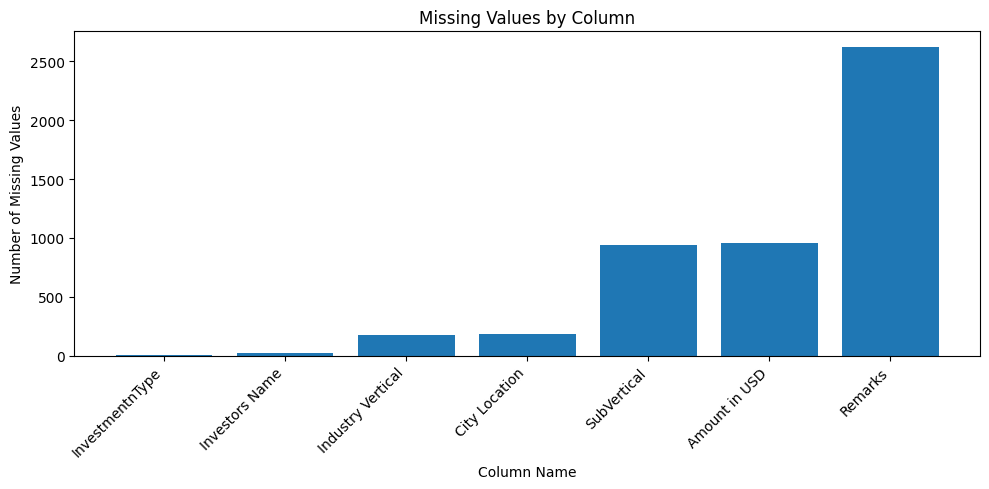

In [10]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values()

plt.figure(figsize=(10, 5))
plt.bar(missing_values.index, missing_values.values)

plt.title("Missing Values by Column")
plt.xlabel("Column Name")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



## 6. Handling Missing Values

Missing values are handled to improve data quality.

- Missing industry, subvertical, city, investor, and investment type values are replaced with "Unknown".
- Missing remarks are replaced with "No Remarks".
- Missing funding amounts are kept unchanged because the actual funding value is not available.

This approach preserves the original meaning of the data.


In [11]:

text_columns = [
    "Industry Vertical",
    "SubVertical",
    "City Location",
    "Investors Name",
    "InvestmentnType"
]

for column in text_columns:
    df[column] = (
        df[column]
        .replace(r"^\s*$", np.nan, regex=True)
        .fillna("Unknown")
    )

if "Remarks" in df.columns:
    df["Remarks"] = (
        df["Remarks"]
        .replace(r"^\s*$", np.nan, regex=True)
        .fillna("No Remarks")
    )

print("Missing categorical values handled!")

print("\nRemaining Missing Values:")
print(df.isnull().sum())


Missing categorical values handled!

Remaining Missing Values:
Sr No                  0
Date dd/mm/yyyy        0
Startup Name           0
Industry Vertical      0
SubVertical            0
City Location          0
Investors Name         0
InvestmentnType        0
Amount in USD        960
Remarks                0
dtype: int64



## 7. Duplicate Records Analysis

Duplicate records are rows that contain exactly the same values as other rows.

In this step, we identify duplicate rows and remove them if they exist. This helps prevent repeated records from affecting the analysis.


In [12]:

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

df = df.drop_duplicates().copy()

print("Dataset Shape After Removing Duplicates:", df.shape)


Number of Duplicate Rows: 0
Dataset Shape After Removing Duplicates: (3044, 10)



## 8. Date Conversion and Year Extraction

The dataset contains startup funding dates. We convert these dates into a proper datetime format using Pandas.

We also extract the year from each date. This helps us analyze funding trends across different years.


In [13]:

df["Date"] = pd.to_datetime(
    df["Date dd/mm/yyyy"],
    dayfirst=True,
    errors="coerce"
)

df["Year"] = df["Date"].dt.year

print("Date conversion completed successfully!")

display(
    df[["Date dd/mm/yyyy", "Date", "Year"]].head(10)
)

print("\nMissing Dates:", df["Date"].isna().sum())


Date conversion completed successfully!


,Date dd/mm/yyyy,Date,Year
0,09/01/2020,2020-01-09,2020.0
1,13/01/2020,2020-01-13,2020.0
2,09/01/2020,2020-01-09,2020.0
3,02/01/2020,2020-01-02,2020.0
4,02/01/2020,2020-01-02,2020.0
5,13/01/2020,2020-01-13,2020.0
6,10/01/2020,2020-01-10,2020.0
7,12/12/2019,2019-12-12,2019.0
8,06/12/2019,2019-12-06,2019.0
9,03/12/2019,2019-12-03,2019.0



Missing Dates: 8



## 9. Cleaning Funding Amounts

The original funding amount column may contain commas, currency symbols, text values, and missing entries.

In this step, we clean the funding amounts and convert valid values into numerical format. A new column named `Amount_Clean` is created so that the original data remains unchanged.

Unknown or undisclosed amounts are treated as missing values, not as zero.


In [14]:

def clean_amount(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    if value.lower() in ["", "unknown", "undisclosed", "nan", "n/a"]:
        return np.nan

    value = value.replace(",", "")
    value = re.sub(r"[^0-9.]", "", value)

    if not value or value.count(".") > 1:
        return np.nan

    try:
        return float(value)
    except ValueError:
        return np.nan


df["Amount_Clean"] = df["Amount in USD"].apply(clean_amount)

print("Funding amounts cleaned successfully!")

print("\nMissing Funding Amounts:",
      df["Amount_Clean"].isna().sum())

print("Valid Funding Amounts:",
      df["Amount_Clean"].notna().sum())

display(df[["Amount in USD", "Amount_Clean"]].head(10))


Funding amounts cleaned successfully!

Missing Funding Amounts: 967
Valid Funding Amounts: 2077


,Amount in USD,Amount_Clean
0,"20,00,00,000",200000000.0
1,"80,48,394",8048394.0
2,"1,83,58,860",18358860.0
3,"30,00,000",3000000.0
4,"18,00,000",1800000.0
5,"90,00,000",9000000.0
6,"15,00,00,000",150000000.0
7,"60,00,000",6000000.0
8,"7,00,00,000",70000000.0
9,"5,00,00,000",50000000.0



## 10. Statistical Analysis of Funding Amounts

Statistical analysis helps us understand the distribution of startup funding.

We calculate the minimum, maximum, mean, and median funding amounts using the cleaned numerical column. Missing funding amounts are excluded from these calculations.


In [15]:
funding = df["Amount_Clean"].dropna()

print("Minimum Funding (USD):", funding.min())
print("Maximum Funding (USD):", funding.max())
print("Average Funding (USD):", round(funding.mean(), 2))
print("Median Funding (USD):", funding.median())
print("Valid Funding Records:", len(funding))


Minimum Funding (USD): 20.0
Maximum Funding (USD): 3900000000.0
Average Funding (USD): 22332168.97
Median Funding (USD): 1750000.0
Valid Funding Records: 2077



## 11. Outlier Detection Using the IQR Method

Outliers are values that differ significantly from most other observations.

In this project, we use the Interquartile Range (IQR) method to identify potential outliers in startup funding amounts.

IQR = Q3 - Q1

Lower Limit = Q1 - 1.5 × IQR

Upper Limit = Q3 + 1.5 × IQR

We will identify outliers but retain them because unusually large funding amounts may represent genuine investments.


In [16]:

funding = df["Amount_Clean"].dropna()

Q1 = funding.quantile(0.25)
Q3 = funding.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = funding[
    (funding < lower_limit) |
    (funding > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(outliers))


Q1: 470000.0
Q3: 8200000.0
IQR: 7730000.0
Lower Limit: -11125000.0
Upper Limit: 19795000.0
Number of Outliers: 288



### Visualization 2: Box Plot of Startup Funding

A box plot shows the spread of funding amounts and highlights potential outliers. Points outside the whiskers represent values that may be unusually high or low.


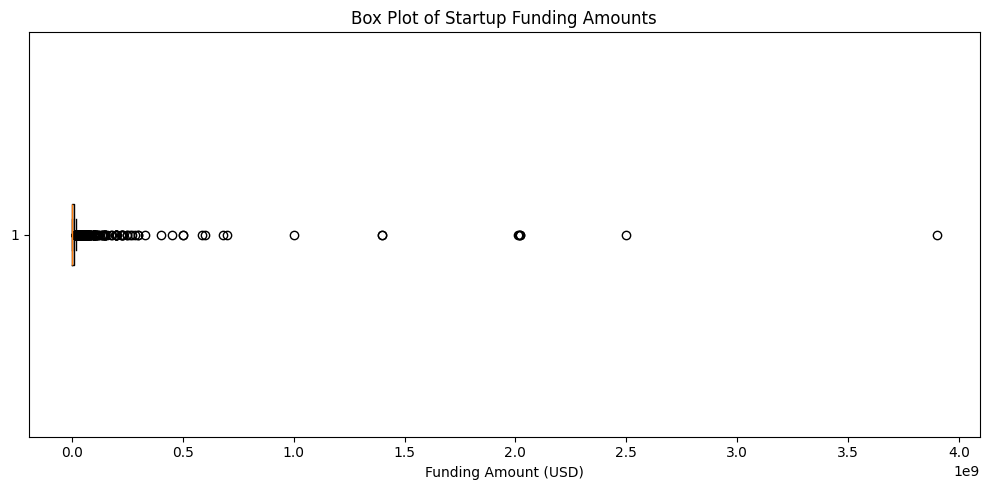

In [17]:

plt.figure(figsize=(10, 5))

plt.boxplot(funding, vert=False)

plt.title("Box Plot of Startup Funding Amounts")
plt.xlabel("Funding Amount (USD)")

plt.tight_layout()
plt.show()


### Visualization 2: Yearly Startup Funding Trend

This line chart shows the total recorded startup funding for each year. It helps us understand how startup funding has changed over time.

The chart uses the cleaned funding amounts and excludes records with missing dates or funding values.

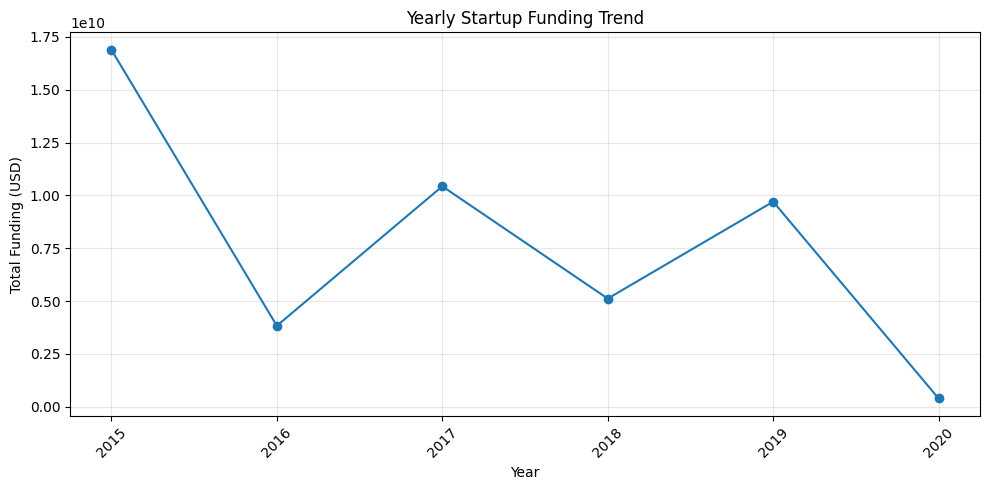

In [18]:
yearly_funding = (
    df.dropna(subset=["Year", "Amount_Clean"])
      .groupby("Year")["Amount_Clean"]
      .sum()
      .sort_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_funding.index,
    yearly_funding.values,
    marker="o"
)

plt.title("Yearly Startup Funding Trend")
plt.xlabel("Year")
plt.ylabel("Total Funding (USD)")
plt.xticks(yearly_funding.index, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Visualization 3: Top 10 Industries by Startup Count

This horizontal bar chart displays the top 10 industries with the highest number of startup records in the dataset.

It helps us understand which industries are most frequently represented in the Indian startup funding dataset.

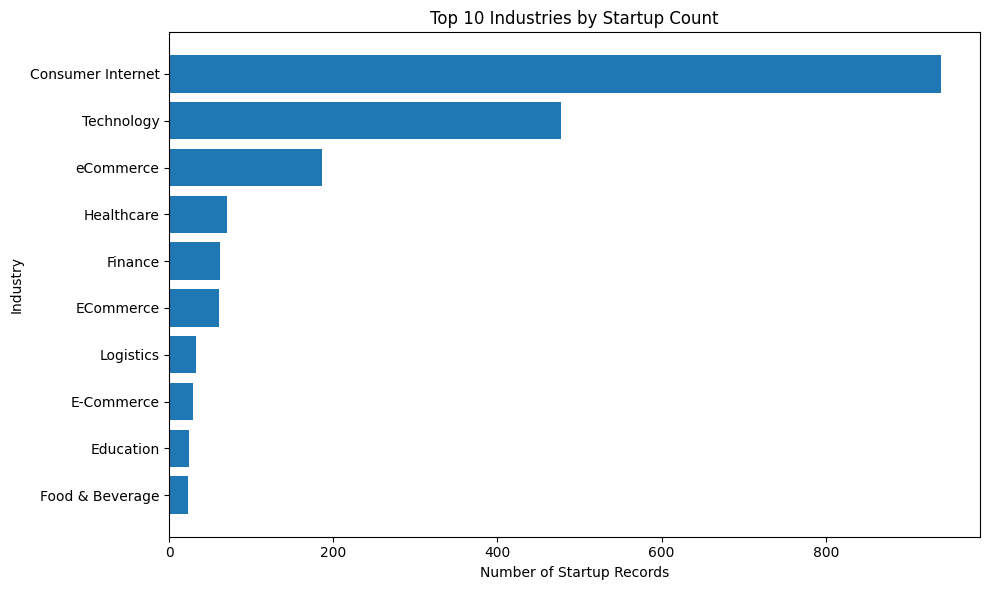

In [19]:
top_industries = (
    df[df["Industry Vertical"] != "Unknown"]
    ["Industry Vertical"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(top_industries.index, top_industries.values)

plt.title("Top 10 Industries by Startup Count")
plt.xlabel("Number of Startup Records")
plt.ylabel("Industry")

plt.tight_layout()
plt.show()

### Visualization 4: Investment Type Distribution

This pie chart shows the distribution of different investment types in the startup funding dataset.

It helps us understand which types of investments appear most frequently in the recorded startup funding data.

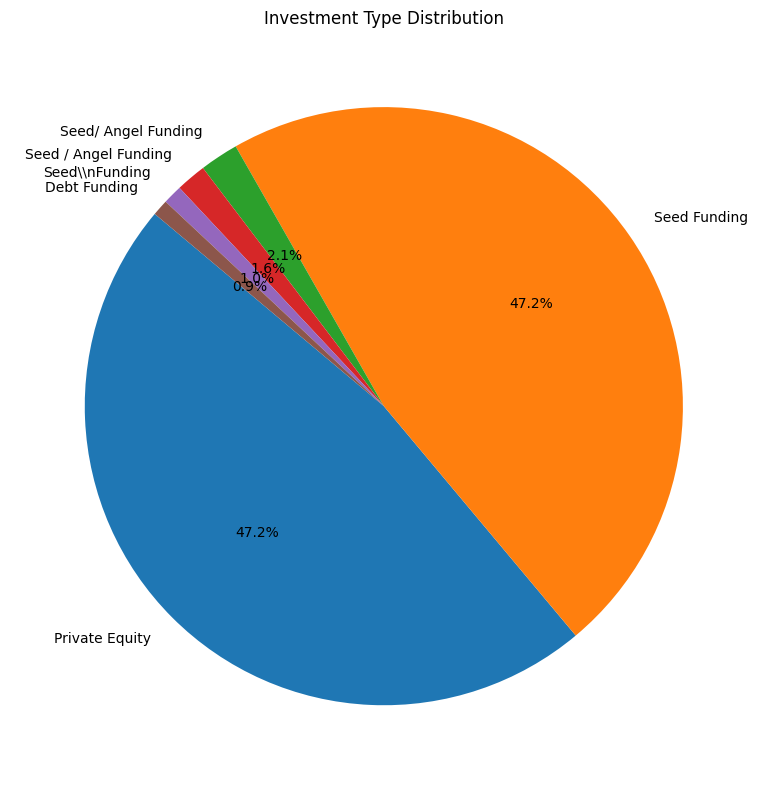

In [20]:
investment_types = (
    df[df["InvestmentnType"] != "Unknown"]["InvestmentnType"]
    .value_counts()
    .head(6)
)

plt.figure(figsize=(8, 8))

plt.pie(
    investment_types.values,
    labels=investment_types.index,
    autopct="%1.1f%%",
    startangle=140
)

plt.title("Investment Type Distribution")
plt.tight_layout()
plt.show()

### Visualization 5: Distribution of Startup Funding Amounts

This histogram shows the distribution of startup funding amounts in the dataset.

It helps us understand how frequently different funding ranges occur. Since funding amounts can vary significantly, a logarithmic scale is used on the horizontal axis to make the distribution easier to examine.

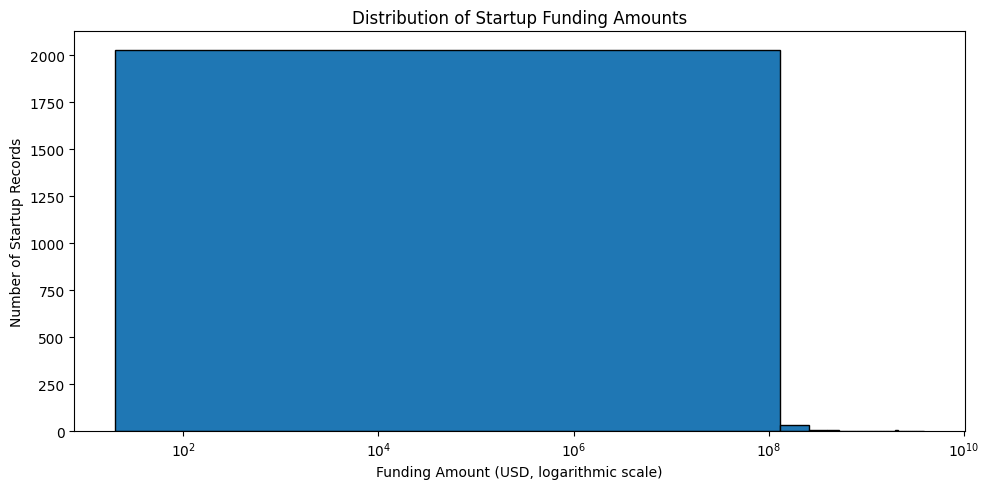

In [21]:
positive_funding = df.loc[
    df["Amount_Clean"] > 0, "Amount_Clean"
].dropna()

plt.figure(figsize=(10, 5))

plt.hist(positive_funding, bins=30, edgecolor="black")

plt.xscale("log")
plt.title("Distribution of Startup Funding Amounts")
plt.xlabel("Funding Amount (USD, logarithmic scale)")
plt.ylabel("Number of Startup Records")

plt.tight_layout()
plt.show()

### Visualization 6: Top 10 Most Funded Startups

This bar chart displays the top 10 startups by total recorded funding amount.

The funding amounts are grouped by startup name and sorted in descending order. This visualization helps compare the total funding recorded for different startups.

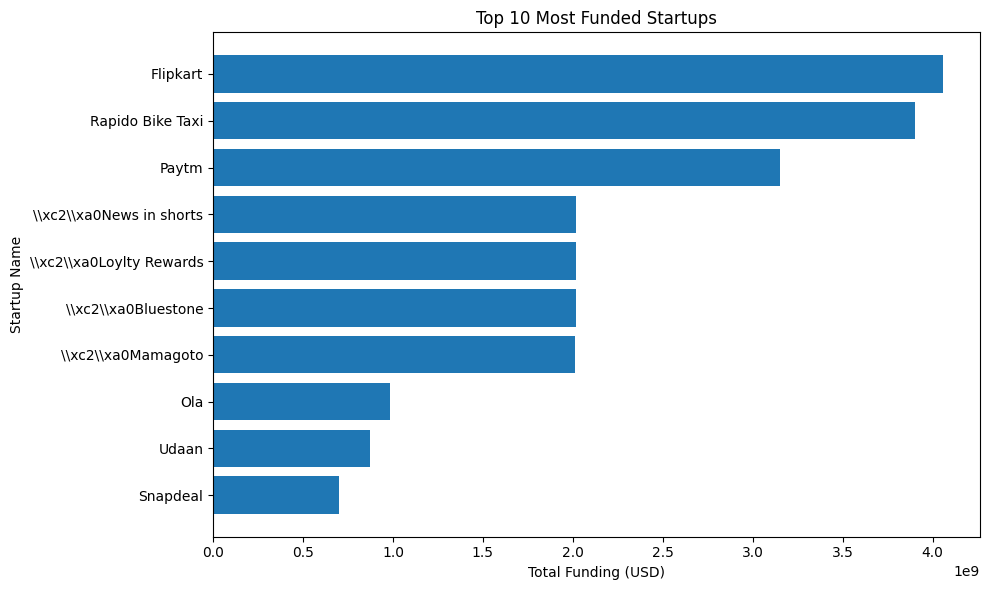

In [22]:
top_startups = (
    df.dropna(subset=["Amount_Clean"])
    .groupby("Startup Name")["Amount_Clean"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(top_startups.index, top_startups.values)

plt.title("Top 10 Most Funded Startups")
plt.xlabel("Total Funding (USD)")
plt.ylabel("Startup Name")

plt.tight_layout()
plt.show()

In [23]:
print("PROJECT INSIGHTS")
print("-" * 40)

print("\nTotal Startup Records:", len(df))

print(
    "Startups with Recorded Funding:",
    df["Amount_Clean"].notna().sum()
)

if not yearly_funding.empty:
    print(
        "\nYear with Highest Total Recorded Funding:",
        int(yearly_funding.idxmax())
    )

if not top_industries.empty:
    print(
        "Industry with Most Startup Records:",
        top_industries.idxmax()
    )

if not investment_types.empty:
    print(
        "Most Frequently Recorded Investment Type:",
        investment_types.idxmax()
    )

if not top_startups.empty:
    print(
        "Startup with Highest Total Recorded Funding:",
        top_startups.idxmax()
    )

PROJECT INSIGHTS
----------------------------------------

Total Startup Records: 3044
Startups with Recorded Funding: 2077

Year with Highest Total Recorded Funding: 2015
Industry with Most Startup Records: Consumer Internet
Most Frequently Recorded Investment Type: Private Equity
Startup with Highest Total Recorded Funding: Flipkart


In [24]:
print("Data Types Before/After Cleaning:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows Remaining:")
print(df.duplicated().sum())

Data Types Before/After Cleaning:
Sr No                         int64
Date dd/mm/yyyy              object
Startup Name                 object
Industry Vertical            object
SubVertical                  object
City Location                object
Investors Name               object
InvestmentnType              object
Amount in USD                object
Remarks                      object
Date                 datetime64[ns]
Year                        float64
Amount_Clean                float64
dtype: object

Missing Values:
Sr No                  0
Date dd/mm/yyyy        0
Startup Name           0
Industry Vertical      0
SubVertical            0
City Location          0
Investors Name         0
InvestmentnType        0
Amount in USD        960
Remarks                0
Date                   8
Year                   8
Amount_Clean         967
dtype: int64

Duplicate Rows Remaining:
0


In [25]:
print("FINAL PROJECT VERIFICATION")
print("-" * 35)

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Data Types Checked:", len(df.dtypes))
print("Cleaned Funding Column Exists:", "Amount_Clean" in df.columns)

print("\nProject verification completed!")

FINAL PROJECT VERIFICATION
-----------------------------------
Dataset Shape: (3044, 13)
Missing Values: 1943
Duplicate Rows: 0
Data Types Checked: 13
Cleaned Funding Column Exists: True

Project verification completed!


## 12. Short Insights Report

The Indian Startup Funding dataset was analyzed using Python, Pandas, NumPy, and Matplotlib.

### Key Findings

- **Data Cleaning:** Missing values were handled where appropriate, duplicate records were checked, and date and funding columns were converted into suitable formats.
- **Outlier Analysis:** The IQR method identified 288 potential outliers in the recorded funding amounts. These values were retained because they may represent genuine large investments.
- **Yearly Funding Trend:** The analysis identified 2015 as the year with the highest total recorded funding in the available date data.
- **Industry Analysis:** Consumer Internet was the most frequently recorded industry in the dataset.
- **Investment Type Analysis:** Private Equity was the most frequently recorded investment type.
- **Startup Analysis:** Flipkart had the highest total recorded funding when funding amounts were grouped by startup name.

### Conclusion

This analysis demonstrates how data cleaning, statistical methods, and visualizations can help identify patterns in Indian startup funding data. The results provide insights into recorded funding trends, industries, investment types, and startups. However, missing values and incomplete records may affect the findings, so the results represent the available dataset rather than the entire Indian startup ecosystem.